## Business Understanding

### Latar Belakang

Pemantauan tutupan dan penggunaan lahan di Jawa Timur masih banyak bergantung pada survei lapangan
dan pemetaan manual yang lambat dan mahal. Citra satelit Sentinel-2 (resolusi 10–20 m, diperbarui
berkala dan gratis) memungkinkan pemetaan permukaan bumi secara otomatis. Proyek ini memakai
wilayah Banyuwangi dan sekitarnya (termasuk sebagian Situbondo dan Lumajang) sebagai wilayah
percontohan, karena memuat seluruh kelas yang dibutuhkan: bangunan, lahan pertanian, perairan,
hutan, dan mangrove.

### Tujuan

1. Memetakan lima kelas tutupan lahan secara otomatis dari citra Sentinel-2 L2A: bangunan,
   lahan pertanian, badan air, hutan, dan hutan mangrove.
2. Membedakan mangrove dari hutan biasa menggunakan komposit B8A–B11–B4.
3. Menyajikan hasil dalam peta interaktif dengan filter per kelas serta ringkasan luas dan
   akurasi model.

### Pengguna dan Manfaat

| Pengguna | Manfaat |
|---|---|
| Pemerintah daerah | Dukungan pemantauan lahan dan tata ruang |
| Peneliti | Dasar analisis perubahan tutupan lahan dan konservasi |
| Masyarakat | Informasi yang mudah diakses tentang kondisi lahan di sekitarnya |

## Implementasi

### Import Library

In [1]:
import os, json, time
import requests
import warnings
import openeo
import glob
import rasterio
import joblib

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.mask import mask
from rasterio.windows import Window
from rasterio.merge import merge
from rasterio.features import sieve, shapes

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

from xgboost import XGBClassifier
from shapely.geometry import shape


### Autentikasi CDSE

In [2]:
conn = openeo.connect('openeo.dataspace.copernicus.eu').authenticate_oidc()

Authenticated using refresh token.


### Mengambil AoI di Wilayah Jawa Timur

In [ ]:
AOI_PATH = './digitizations/jatim_raster.geojson'
aoi_gdf = gpd.read_file(AOI_PATH)
aoi_geom = aoi_gdf.geometry.unary_union

BANDS = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12']
W, S, E, N = aoi_gdf.total_bounds
NX, NY = 8, 5
TEMPORAL = ['2026-06-01', '2026-09-30']
MAX_CLOUD = 40

JOB_OPTIONS = {
    "executor-memory": "4G",
    "executor-memoryOverhead": "3G",
}

MAX_PARALLEL = 2
MAX_RETRY = 2
STATE_FILE = './other/tiles_state_jatim.json'

xs = np.linspace(W, E, NX + 1)
ys = np.linspace(S, N, NY + 1)

def build_cube(w, s, e, n):
    cube = conn.load_collection(
        'SENTINEL2_L2A',
        spatial_extent={"west": float(w), "south": float(s), "east": float(e), "north": float(n), "crs": "EPSG:4326"},
        temporal_extent=TEMPORAL,
        bands=BANDS + ['SCL'],
        max_cloud_cover=MAX_CLOUD,
    )

    scl = cube.band('SCL')
    bad = (scl == 0) | (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10) | (scl == 11)
    cube = cube.mask(bad).filter_bands(BANDS)
    cube = cube.reduce_dimension(dimension='t', reducer='median')
    cube = cube.resample_spatial(resolution=20, projection=32749)
    return cube.save_result(format='GTiff')

from shapely.geometry import box

TILES = {}
for i in range(NX):
    for j in range(NY):
        tile_box = box(xs[i], ys[j], xs[i + 1], ys[j + 1])
        if aoi_geom.intersects(tile_box):
            TILES[f'tile_{i}_{j}'] = (xs[i], ys[j], xs[i + 1], ys[j + 1])

print(len(TILES), 'ubin (dari', NX * NY, 'total, setelah filter AoI)')


In [ ]:
def load_state():
    return json.load(open(STATE_FILE)) if os.path.exists(STATE_FILE) else {}

def save_state(st):
    json.dump(st, open(STATE_FILE, 'w'), indent=2)

def refresh(st):
    for name, info in st.items():
        if info.get('status') in ('finished', 'error', 'canceled'):
            continue

        info['status'] = conn.job(info['job_id']).status()

def run_all(poll=60):
    st = load_state()

    while True:
        refresh(st)
        
        running = [n for n, v in st.items() if v['status'] in ('created', 'queued', 'running')]
        todo = []

        for name in TILES:
            v = st.get(name)
            if v is None:
                todo.append(name)

            elif v['status'] in ('error', 'canceled') and v.get('tries', 1) <= MAX_RETRY:
                todo.append(name)

        # mulai ubin baru sesuai slot yang tersedia
        for name in todo:
            if len(running) >= MAX_PARALLEL:
                break

            w, s, e, n = TILES[name]
            job = build_cube(w, s, e, n).create_job(title=name, job_options=JOB_OPTIONS)
            job.start()
            tries = st.get(name, {}).get('tries', 0) + 1
            st[name] = {'job_id': job.job_id, 'status': 'queued', 'tries': tries}
            
            running.append(name)
            print('mulai', name, job.job_id, f'(percobaan {tries})')

        save_state(st)

        done = sum(v['status'] == 'finished' for v in st.values())
        failed = [n for n, v in st.items() if v['status'] == 'error' and v.get('tries', 1) > MAX_RETRY]

        print(time.strftime('%H:%M:%S'), f'selesai {done}/{len(TILES)}, jalan {len(running)}, gagal permanen {failed}')

        if done == len(TILES) or (not running and not todo):
            return st
        
        time.sleep(poll)

state = run_all()

Cell untuk melihat penyebab kegagalan running diatas

In [ ]:
# contoh: lihat log ubin yang gagal
# name = 'tile_0_0'
# print(conn.job(state[name]['job_id']).logs(level='ERROR')[-3:])

#### Unduh hasil

> Bisa dilanjutkan kalau koneksi putus

In [ ]:
def download_resume(url, path, retries=30, chunk=1024 * 1024):
    for attempt in range(retries):
        done = os.path.getsize(path) if os.path.exists(path) else 0
        headers = {'Range': f'bytes={done}-'} if done else {}
        try:
            with requests.get(url, headers=headers, stream=True, timeout=60) as r:
                if r.status_code == 416:          # sudah lengkap
                    return
                r.raise_for_status()
                if done and r.status_code != 206:  # server abaikan Range -> ulang dari awal
                    done = 0
                with open(path, 'ab' if done else 'wb') as f:
                    for part in r.iter_content(chunk):
                        f.write(part)
            return
        except (requests.exceptions.RequestException, OSError) as e:
            print(f'  percobaan {attempt + 1} gagal ({type(e).__name__}), ulangi...')
            time.sleep(5)
    raise RuntimeError('Unduhan gagal setelah banyak percobaan')

os.makedirs('openeo_out', exist_ok=True)
for name, info in load_state().items():
    if info['status'] != 'finished':
        continue
    for asset in conn.job(info['job_id']).get_results().get_assets():
        if asset.key.lower().endswith(('.tif', '.tiff')):
            target = os.path.join('openeo_out', f'{name}.tif')
            print('unduh', name)
            download_resume(asset.href, target)

#### Cek tiap ubin, lalu gabung jadi satu GeoTIFF

In [ ]:
files = sorted(glob.glob('openeo_out/tile_*.tif'))

for p in files:
    with rasterio.open(p) as src:
        print(p, src.count, 'band,', src.width, 'x', src.height, src.crs)
        
print(len(files), 'dari', len(TILES), 'ubin')

In [ ]:
srcs = [rasterio.open(p) for p in files]

print('tipe:', {s.dtypes[0] for s in srcs}, '| nodata:', {s.nodata for s in srcs})

merge(srcs, dst_path='./openeo_out/s2_aoi_20m.tif',
      dst_kwds={'compress': 'deflate', 'tiled': True, 'BIGTIFF': 'IF_SAFER'})

for s in srcs:
    s.close()

with rasterio.open('./openeo_out/s2_aoi_20m.tif', 'r+') as dst:
    dst.descriptions = ('B2', 'B3', 'B4', 'B8', 'B8A', 'B11', 'B12')
    print(dst.count, 'band,', dst.width, 'x', dst.height, dst.crs, dst.res, '| nodata:', dst.nodata)

#### Mengecek Skala

In [ ]:
for p in files[:3]:
    with rasterio.open(p) as s:
        a = s.read(3)    # band 3 = B4
        valid = a[a != s.nodata] if s.nodata is not None else a
        
        print(p, s.dtypes[0], s.nodata, '| min', valid.min(), 'maks', valid.max(),
              '| nodata', round(float((a == s.nodata).mean()) * 100, 1), '%')

### Sampel, Fitur, Model, dan Peta

In [76]:
RASTER = './openeo_out/s2_aoi_20m.tif'
SAMPLES = './digitizations/clean/training_samples_clean.geojson'
OUT_DIR = 'outputs'

# Raster OpenEO = bilangan bulat (reflektansi * 10000)
SCALE = 10000.0

# Batasi piksel per poligon agar poligon besar tidak mendominasi
MAX_PX_PER_POLY = 300

RANDOM_STATE = 42
RGB_ORDER = ('B8A', 'B11', 'B4')
BAND_NAMES = ['B2', 'B3', 'B4', 'B8', 'B8A', 'B11', 'B12']

os.makedirs(OUT_DIR, exist_ok=True)

# ID kelas harus sama dengan yang di dalam digitasi
CLASSES = {
    1: ('built_up', 'Bangunan', '#e53935'),
    2: ('farmland', 'Lahan pertanian', '#fdd835'),
    3: ('water', 'Badan air', '#1e88e5'),
    4: ('forest', 'Hutan', '#2e7d32'),
    5: ('mangrove', 'Hutan mangrove', '#00e5c0')
}

CODE2ID = {v[0]: k for k, v in CLASSES.items()}
NAMES = [CLASSES[i][1] for i in range(1, 6)]

In [77]:
with rasterio.open(RASTER) as src:
    print(src.count, 'band,', src.width, 'x', src.height, src.crs, src.res, src.dtypes[0], 'nodata =', src.nodata)

    NODATA, R_CRS, R_RES = src.nodata, src.crs, src.res

    # Raster harus 7 band: B2,B3,B4,B8,B8A,B11,B12
    assert src.count == 7

samples = gpd.read_file(SAMPLES).to_crs(R_CRS).reset_index(drop=True)
samples['class_id'] = samples['class'].map(CODE2ID)

assert samples['class_id'].notna().all(), f"kelas tak dikenal: {samples.loc[samples['class_id'].isna(), 'class'].unique()}"

samples['poly_id'] = samples.index

print(samples['class'].value_counts())

7 band, 7718 x 7143 EPSG:32749 (20.0, 20.0) int16 nodata = -32768.0
class
forest      100
farmland     99
water        84
built_up     68
mangrove     64
Name: count, dtype: int64


#### Ekstraksi Piksel + Indeks

In [78]:
EPS = 1e-6
FEATURES = BAND_NAMES + ['NDVI', 'NDWI', 'NDBI', 'MNDWI', 'NDMI']

def nd(a, b):
    return (a - b) / (a + b + EPS)

def feature_stack(refl):
    """refl: (7, ...) reflektansi 0-1  ->  (12, ...) = 7 band + 5 indeks"""

    B2, B3, B4, B8, B8A, B11, B12 = refl

    idx = np.stack([
        nd(B8, B4),     # NDVI  vegetasi
        nd(B3, B8),     # NDWI  air
        nd(B11, B8),    # NDBI  lahan terbangun
        nd(B3, B11),    # MNDWI air (SWIR)
        nd(B8A, B11)    # NDMI  kelembapan vegetasi
    ])
    
    return np.concatenate([refl, idx], axis=0)

rng = np.random.default_rng(RANDOM_STATE)
parts = []

with rasterio.open(RASTER) as src:
    for _, r in samples.iterrows():
        # Poligon sempit: coba all_touched
        for all_touched in (False, True):
            data, tr = mask(src, [r.geometry], crop=True, all_touched=all_touched, filled=False)
            inside = ~np.ma.getmaskarray(data).any(axis=0)
            valid = inside if NODATA is None else inside & (data.data != NODATA).all(axis=0)

            if valid.sum() > 0:
                break

        ys, xs = np.nonzero(valid)

        if len(ys) == 0:
            print('poligon tanpa piksel valid:', r['poly_id'], r['class']); continue
        
        if len(ys) > MAX_PX_PER_POLY:
            sel = rng.choice(len(ys), MAX_PX_PER_POLY, replace=False); ys, xs = ys[sel], xs[sel]

        refl = np.clip(data.data[:, ys, xs].astype(np.float32) / SCALE, 0, 1)
        feats = feature_stack(refl)
        gx, gy = rasterio.transform.xy(tr, ys, xs)
        d = pd.DataFrame(feats.T, columns=FEATURES)

        d.insert(0, 'y', gy); d.insert(0, 'x', gx)
        d.insert(0, 'class_id', int(r['class_id'])); d.insert(0, 'class', r['class']); d.insert(0, 'poly_id', int(r['poly_id']))

        parts.append(d)

df = pd.concat(parts, ignore_index=True)

df.to_csv(f'{OUT_DIR}/training_pixels.csv', index=False)

print(len(df), 'piksel ->', f'{OUT_DIR}/training_pixels.csv')
print(df.groupby('class').agg(piksel=('poly_id', 'size'), poligon=('poly_id', 'nunique')))

52157 piksel -> outputs/training_pixels.csv
          piksel  poligon
class                    
built_up    3369       68
farmland    5852       99
forest     24747      100
mangrove    2871       64
water      15318       84


#### Tanda Spektral dan Band Paling Membedakan

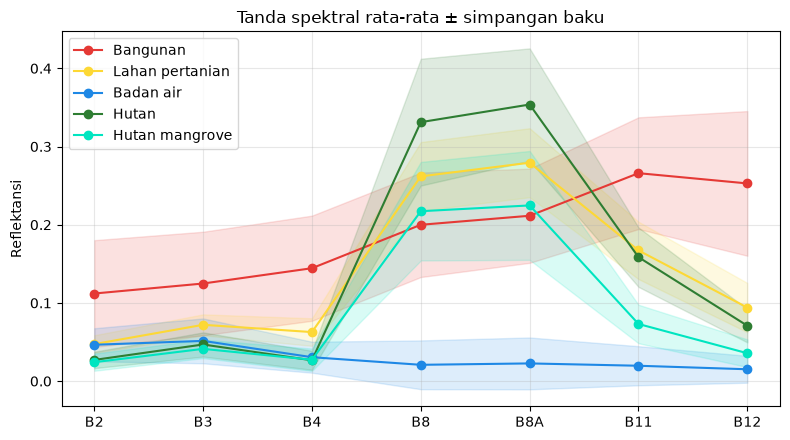

In [79]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for cid, (code_, label, color) in CLASSES.items():
    sub = df[df.class_id == cid][BAND_NAMES]
    m, s = sub.mean(), sub.std()
    
    ax.plot(BAND_NAMES, m, marker='o', color=color, label=label)
    ax.fill_between(BAND_NAMES, m - s, m + s, color=color, alpha=0.15)

ax.set_ylabel('Reflektansi')
ax.set_title('Tanda spektral rata-rata ± simpangan baku')
ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/tanda_spektral.png', dpi=150)
plt.show()

In [80]:
# Seberapa baik tiap fitur memisahkan satu kelas dari sisanya (0.5 = tidak berguna, 1.0 = sempurna)
sep = pd.DataFrame({
    CLASSES[cid][1]: {f: max(roc_auc_score(df.class_id == cid, df[f]), 1 - roc_auc_score(df.class_id == cid, df[f])) for f in FEATURES}
    for cid in CLASSES
}).round(3)

display(sep)

,Bangunan,Lahan pertanian,Badan air,Hutan,Hutan mangrove
B2,0.960,0.762,0.684,0.816,0.756
B3,0.938,0.818,0.578,0.631,0.676
B4,0.988,0.886,0.594,0.674,0.594
B8,0.600,0.547,0.996,0.930,0.556
B8A,0.618,0.529,0.997,0.947,0.580
B11,0.955,0.699,0.990,0.757,0.688
B12,0.997,0.795,0.980,0.698,0.676
NDVI,0.696,0.583,0.994,0.968,0.612
NDWI,0.690,0.580,0.996,0.969,0.604
NDBI,0.932,0.550,0.889,0.863,0.905


In [81]:
# Khusus mangrove vs hutan
sub = df[df.class_id.isin([4, 5])]
mh = {f: max(roc_auc_score(sub.class_id == 5, sub[f]), 1 - roc_auc_score(sub.class_id == 5, sub[f])) for f in FEATURES}

print('Mangrove vs Hutan, fitur terbaik:')
print(pd.Series(mh).sort_values(ascending=False).round(3).head(8))

sep.to_csv(f'{OUT_DIR}/separabilitas_fitur.csv')

Mangrove vs Hutan, fitur terbaik:
MNDWI    0.985
B11      0.979
B12      0.933
B8A      0.921
B8       0.882
NDBI     0.836
NDMI     0.819
NDWI     0.729
dtype: float64


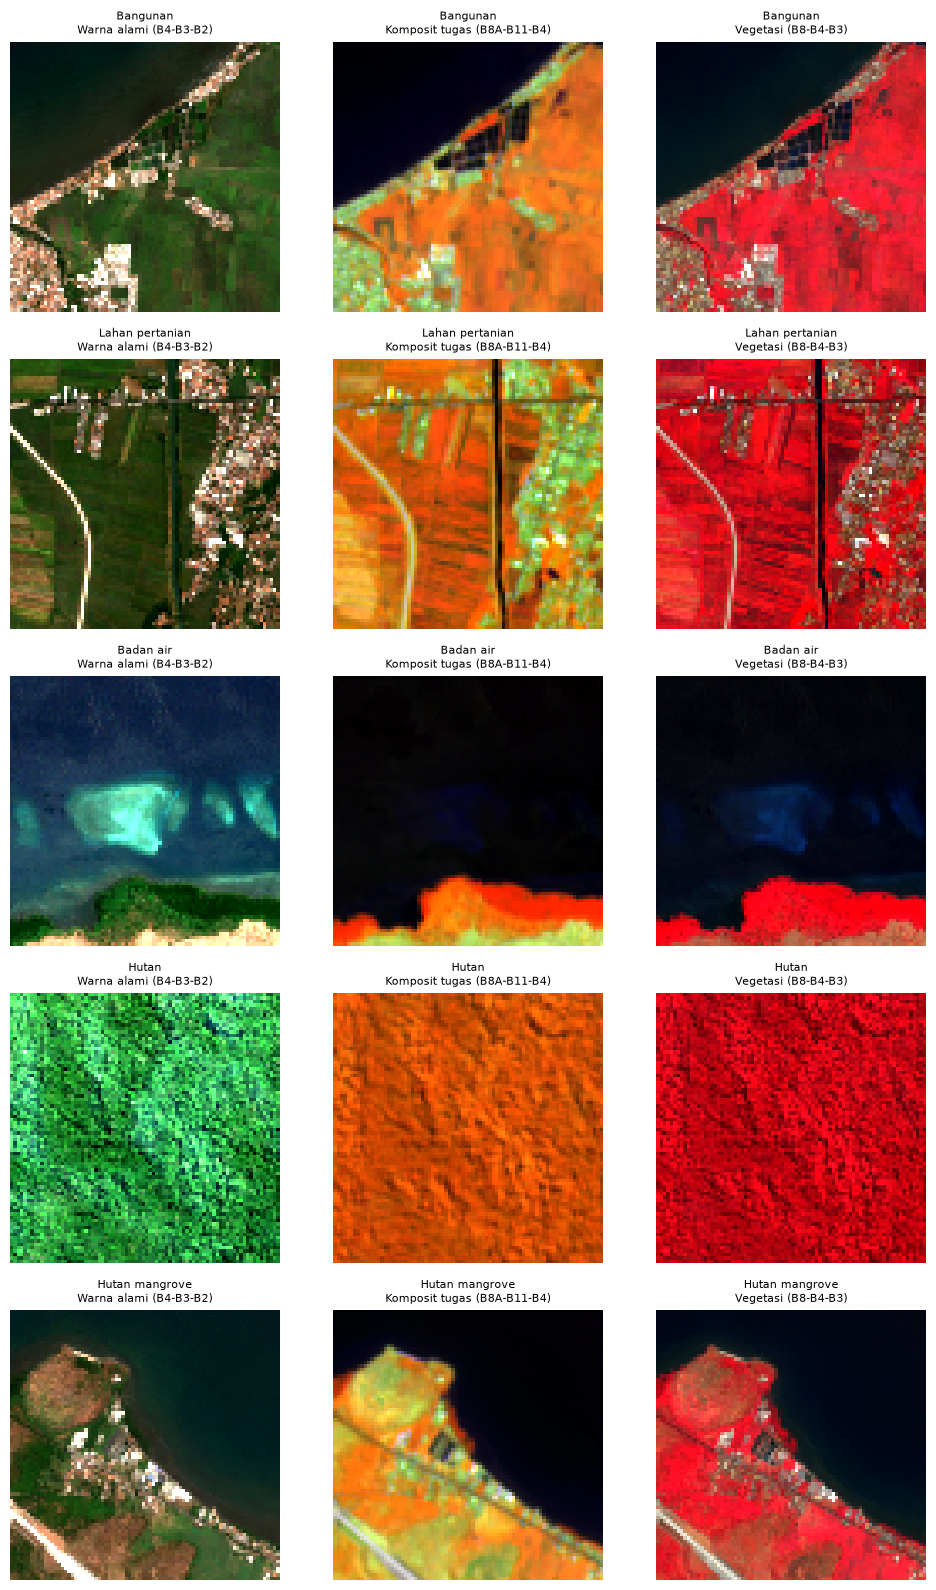

In [82]:
# Bandingkan komposit untuk satu contoh poligon per kelas
def window_around(src, geom, half=40):
    row, col = src.index(geom.centroid.x, geom.centroid.y)

    arr = src.read(window=Window(col - half, row - half, 2 * half, 2 * half), boundless=True,
                   fill_value=NODATA if NODATA is not None else 0).astype(np.float32)
    
    if NODATA is not None:
        arr[arr == NODATA] = np.nan

    return arr / SCALE

def comp(arr, bands):
    img = np.dstack([arr[BAND_NAMES.index(b)] for b in bands])
    lo, hi = np.nanpercentile(img, (2, 98))

    return np.clip((img - lo) / (hi - lo + 1e-9), 0, 1)

COMPS = {
    'Warna alami (B4-B3-B2)': ('B4', 'B3', 'B2'),
    f'Komposit tugas ({"-".join(RGB_ORDER)})': RGB_ORDER,
    'Vegetasi (B8-B4-B3)': ('B8', 'B4', 'B3')
}

fig, axes = plt.subplots(5, 3, figsize=(10, 16))

with rasterio.open(RASTER) as src:
    for i, cid in enumerate(CLASSES):
        g = samples[samples.class_id == cid].sample(1, random_state=RANDOM_STATE).geometry.iloc[0]
        arr = window_around(src, g)

        for j, (title, bands) in enumerate(COMPS.items()):
            axes[i, j].imshow(comp(arr, bands)); axes[i, j].axis('off')
            axes[i, j].set_title(f'{CLASSES[cid][1]}\n{title}', fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/perbandingan_komposit.png', dpi=130)
plt.show()

#### Model dan Evaluasi

Data dibagi **per poligon** (bukan per piksel), supaya piksel bertetangga dari poligon yang sama tidak muncul di data latih dan uji sekaligus. Pembagian tetap menjaga proporsi kelas.

In [83]:
X = df[FEATURES].values.astype(np.float32)
y = df['class_id'].values - 1
g = df['poly_id'].values

# hold-out uji 20% poligon
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr, te = next(sgkf.split(X, y, g))
X_tr, X_te, y_tr, y_te, g_tr = X[tr], X[te], y[tr], y[te], g[tr]

print('piksel latih/uji :', len(tr), len(te))
print('poligon uji per kelas:\n', df.iloc[te].groupby('class').poly_id.nunique().to_string())

def make_model(name):
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)
    
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                         tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []

for name in ['RandomForest', 'XGBoost']:
    res = cross_validate(make_model(name), X_tr, y_tr, groups=g_tr, cv=cv, scoring=['accuracy', 'f1_macro'])
    rows.append({'model': name, 'akurasi_cv': res['test_accuracy'].mean(), 'std': res['test_accuracy'].std(), 'f1_macro_cv': res['test_f1_macro'].mean()})

cv_table = pd.DataFrame(rows).round(4)

display(cv_table)

BEST = cv_table.sort_values('f1_macro_cv', ascending=False).iloc[0]['model']

print('Model terpilih:', BEST)

piksel latih/uji : 41719 10438
poligon uji per kelas:
 class
built_up    13
farmland    20
forest      20
mangrove    12
water       17


,model,akurasi_cv,std,f1_macro_cv
0,RandomForest,0.9703,0.0058,0.9444
1,XGBoost,0.9708,0.0047,0.9468


Model terpilih: XGBoost


Akurasi uji = 0.9556 | F1 macro = 0.9337

                 precision    recall  f1-score   support

       Bangunan      0.969     0.967     0.968       673
Lahan pertanian      0.826     0.865     0.845      1172
      Badan air      0.984     0.980     0.982      3065
          Hutan      0.976     0.965     0.971      4952
 Hutan mangrove      0.894     0.911     0.903       576

       accuracy                          0.956     10438
      macro avg      0.930     0.938     0.934     10438
   weighted avg      0.957     0.956     0.956     10438



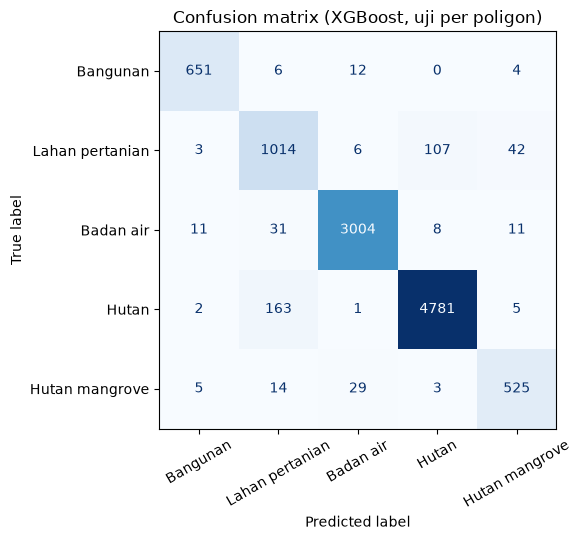

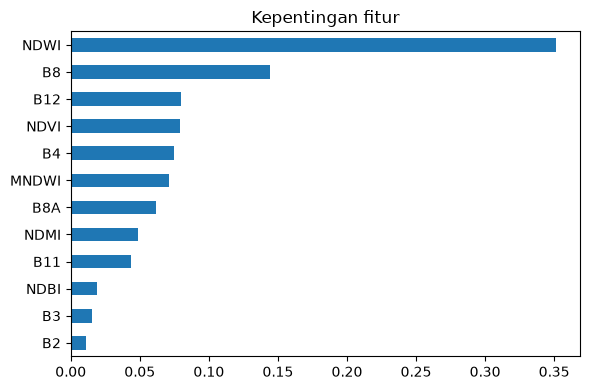

['outputs/model.joblib']

In [84]:
model = make_model(BEST).fit(X_tr, y_tr)
pred = model.predict(X_te)
acc = accuracy_score(y_te, pred)
f1m = f1_score(y_te, pred, average='macro')

print(f'Akurasi uji = {acc:.4f} | F1 macro = {f1m:.4f}\n')
print(classification_report(y_te, pred, labels=range(5), target_names=NAMES, digits=3, zero_division=0))

cm = confusion_matrix(y_te, pred, labels=range(5))
fig, ax = plt.subplots(figsize=(6.5, 5.5))

ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(ax=ax, cmap='Blues', xticks_rotation=30, colorbar=False)

ax.set_title(f'Confusion matrix ({BEST}, uji per poligon)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=150); plt.show()

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

imp.plot.barh(figsize=(6, 4), title='Kepentingan fitur'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_importance.png', dpi=150); plt.show()

metrics = {
    'model': BEST, 'akurasi_uji': float(acc), 'f1_macro_uji': float(f1m),
    'cv': cv_table.to_dict('records'),
    'laporan': classification_report(y_te, pred, labels=range(5), target_names=NAMES, output_dict=True, zero_division=0),
    'piksel_latih': int(len(tr)), 'piksel_uji': int(len(te)),
    'poligon_per_kelas': df.groupby('class').poly_id.nunique().to_dict(),
}

json.dump(metrics, open(f'{OUT_DIR}/metrics.json', 'w'), indent=2, ensure_ascii=False)

# model akhir untuk peta: dilatih ulang dengan SEMUA sampel (angka akurasi di atas tetap dari model hold-out)
final = make_model(BEST).fit(X, y)
joblib.dump(final, f'{OUT_DIR}/model.joblib')

#### Klasifikasi Seluruh Raster

In [ ]:
CLS_TIF = f'{OUT_DIR}/klasifikasi_20m.tif'
ROWS = 256

with rasterio.open(RASTER) as src:
    profile = dict(driver='GTiff', height=src.height, width=src.width, count=1, dtype='uint8',
                   crs=src.crs, transform=src.transform, nodata=0, compress='deflate')
    
    counts = np.zeros(6, dtype=np.int64)

    with rasterio.open(CLS_TIF, 'w', **profile) as dst:
        for r0 in range(0, src.height, ROWS):
            h = min(ROWS, src.height - r0)
            win = Window(0, r0, src.width, h)
            arr = src.read(window=win)
            valid = np.ones(arr.shape[1:], bool) if NODATA is None else (arr != NODATA).all(axis=0)
            out = np.zeros(arr.shape[1:], np.uint8)

            if valid.any():
                refl = np.clip(arr[:, valid].astype(np.float32) / SCALE, 0, 1)
                out[valid] = final.predict(feature_stack(refl).T).astype(np.uint8) + 1

            counts += np.bincount(out.ravel(), minlength=6)
            dst.write(out, 1, window=win)

            if (r0 // ROWS) % 10 == 0:
                print(f'baris {r0}/{src.height}', end='\r')

px_km2 = R_RES[0] * R_RES[1] / 1e6

area = pd.DataFrame({'kelas': NAMES, 'kode': [CLASSES[i][0] for i in range(1, 6)],
                     'piksel': counts[1:], 'luas_km2': (counts[1:] * px_km2).round(2)})

area['persen'] = (100 * area.piksel / area.piksel.sum()).round(2)

area.to_csv(f'{OUT_DIR}/luas_per_kelas.csv', index=False)
display(area)

,kelas,kode,piksel,luas_km2,persen
0,Bangunan,built_up,3602651,1441.06,6.61
1,Lahan pertanian,farmland,8973893,3589.56,16.46
2,Badan air,water,24293002,9717.20,44.55
3,Hutan,forest,17424904,6969.96,31.95
4,Hutan mangrove,mangrove,237394,94.96,0.44


#### Poligon GeoJSON per Kelas (untuk Leaflet)

Hasil raster dibersihkan dari bercak kecil (`SIEVE_PX`), diubah jadi poligon, disederhanakan, dan disimpan per kelas dalam EPSG:4326.
Naikkan `SIEVE_PX` / `SIMPLIFY_M` kalau file terlalu besar.

In [86]:
# Buang bercak <50 piksel (= 2 ha)
SIEVE_PX = 50

# Penyerdehanaan garis (meter)
SIMPLIFY_M = 20

with rasterio.open(CLS_TIF) as src:
    cls = src.read(1); tfm = src.transform; crs = src.crs

cls = sieve(cls, size=SIEVE_PX, mask=cls > 0, connectivity=4)

recs = [(shape(geom), int(v)) for geom, v in shapes(cls, mask=cls > 0, transform=tfm)]
poly = gpd.GeoDataFrame({'class_id': [v for _, v in recs]}, geometry=[g_ for g_, _ in recs], crs=crs)

poly['class'] = poly.class_id.map(lambda i: CLASSES[i][0])
poly['label'] = poly.class_id.map(lambda i: CLASSES[i][1])
poly['luas_ha'] = (poly.geometry.area / 1e4).round(2)
poly['geometry'] = poly.geometry.simplify(SIMPLIFY_M, preserve_topology=True)

poly = poly.to_crs(4326)

try:
    poly['geometry'] = poly.geometry.set_precision(1e-5)     # kurangi digit koordinat -> file lebih kecil
except Exception:
    pass

for cid, (code_, label, _) in CLASSES.items():
    part = poly[poly.class_id == cid]
    path = f'{OUT_DIR}/hasil_{code_}.geojson'
    part.to_file(path, driver='GeoJSON')

    print(f'{label:18s} {len(part):7d} poligon  {os.path.getsize(path) / 1e6:7.1f} MB')

Bangunan              6172 poligon      7.6 MB
Lahan pertanian       4794 poligon     11.8 MB
Badan air              193 poligon      0.6 MB
Hutan                 5165 poligon     10.3 MB
Hutan mangrove         237 poligon      0.3 MB
